# Goal

The goal of this project is to perform exploratory data analysis on the IEEE-CIS Fraud Detection dataset and identify patterns that may help separate fraudulent from non-fraudulent transactions.

This is a medium-to-large, highly imbalanced tabular dataset with hundreds of anonymized features. The project focuses on:

- memory-aware data handling;
- missingness analysis;
- fraud-rate analysis by interpretable feature groups;
- identifying useful preprocessing decisions for later modeling.

This notebook is focused on EDA. Modeling, experiment tracking, SHAP analysis, and deployment will be handled in separate notebooks/modules.

This notebook is rerunnable in Google Colab. After loading the Kaggle training files, label-aware EDA is restricted to the earlier 80% of transactions by `TransactionDT`. The latest 20% is reserved for later model evaluation. Run all cells from the top in a fresh Colab runtime.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import plotly.express as px

try:
    from google.colab import userdata
    key = userdata.get("KAGGLE_API_TOKEN")
    if key:
        os.environ["KAGGLE_API_TOKEN"] = key.strip()
except ImportError:
    pass

In [2]:
# Install the Kaggle CLI only when this Colab runtime needs it.
import importlib.metadata
import subprocess
import sys

try:
    kaggle_version = importlib.metadata.version("kaggle")
except importlib.metadata.PackageNotFoundError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    kaggle_version = importlib.metadata.version("kaggle")
print("Kaggle CLI:", kaggle_version)

Kaggle CLI: 2.0.2


# Helper functions

In [3]:
import warnings
from contextlib import nullcontext

def reduce_memory(df: pd.DataFrame, verbose: bool = True, ignore_warnings: bool = False, inplace: bool = True) -> pd.DataFrame:
    """
    Downcast numeric columns to reduce DataFrame memory usage.
    """
    if not inplace:
        df = df.copy()

    start_mem = df.memory_usage(deep=True).sum() / 1e6

    warning_context = warnings.catch_warnings() if ignore_warnings else nullcontext()

    with warning_context:
        if ignore_warnings:
            warnings.filterwarnings(
                "ignore",
                category=RuntimeWarning,
                message="overflow encountered in cast",
            )

        for col in df.columns:
            series = df[col]

            if pd.api.types.is_integer_dtype(series):
                c_min = series.min()
                c_max = series.max()

                if c_min >= np.iinfo(np.int8).min and c_max <= np.iinfo(np.int8).max:
                    df[col] = series.astype(np.int8)
                elif c_min >= np.iinfo(np.int16).min and c_max <= np.iinfo(np.int16).max:
                    df[col] = series.astype(np.int16)
                elif c_min >= np.iinfo(np.int32).min and c_max <= np.iinfo(np.int32).max:
                    df[col] = series.astype(np.int32)
                else:
                    df[col] = series.astype(np.int64)

            elif pd.api.types.is_float_dtype(series):
                c_min = series.min()
                c_max = series.max()

                if c_min >= np.finfo(np.float32).min and c_max <= np.finfo(np.float32).max:
                    df[col] = series.astype(np.float32)
                else:
                    df[col] = series.astype(np.float64)

    end_mem = df.memory_usage(deep=True).sum() / 1e6

    if verbose:
        reduction = 100 * (start_mem - end_mem) / start_mem if start_mem else 0
        print(f"Memory: {start_mem:.2f} MB → {end_mem:.2f} MB ({reduction:.1f}% reduction)")

    return df

In [4]:
def missing_values_report(
    df: pd.DataFrame,
    columns_to_skip_prefix: list[str] | None = None,
) -> pd.DataFrame:
  """
    Helper function that gives info about missing values per column.
  """
  if columns_to_skip_prefix is None:
      columns_to_skip_prefix = []

  results = []

  for column in df.columns:
      if any(column.startswith(prefix) for prefix in columns_to_skip_prefix):
          continue

      missing_count = df[column].isna().sum()
      present_count = df[column].notna().sum()
      total_count = len(df)

      results.append(
          {
              "column": column,
              "dtype": df[column].dtype,
              "total_count": total_count,
              "present_count": present_count,
              "present_percent": present_count / total_count,
              "missing_count": missing_count,
              "missing_percent": missing_count / total_count,
          }
      )

  return (
      pd.DataFrame(results)
      .sort_values("missing_percent", ascending=False)
      .reset_index(drop=True)
  )

In [5]:
def get_missingness_vs_target_report(df: pd.DataFrame, target_col: str, columns_to_skip_prefix: list[str] | None = None) -> pd.DataFrame:
    """
    Generates a report based on a comparison of the fraud rate when a column is missing vs. when that column is present.
    """
    if columns_to_skip_prefix is None:
        columns_to_skip_prefix = []

    global_fraud_rate = df[target_col].mean()
    results = []

    for column in df.columns:
        if column == target_col:
            continue

        if any(column.startswith(prefix) for prefix in columns_to_skip_prefix):
            continue

        missing_mask = df[column].isna()
        present_mask = ~missing_mask

        missing_count = missing_mask.sum()
        present_count = present_mask.sum()

        if missing_count == 0 or present_count == 0:
            continue

        fraud_count_when_missing = df.loc[missing_mask, target_col].sum()
        fraud_count_when_present = df.loc[present_mask, target_col].sum()

        fraud_rate_when_missing = fraud_count_when_missing / missing_count
        fraud_rate_when_present = fraud_count_when_present / present_count

        results.append({
            "column": column,
            "dtype": df[column].dtype,
            "missing_count": missing_count,
            "missing_percent": missing_count / len(df) * 100,
            "present_count": present_count,
            "present_percent": present_count / len(df) * 100,
            "fraud_count_when_missing": fraud_count_when_missing,
            "fraud_count_when_present": fraud_count_when_present,
            "fraud_rate_when_missing": fraud_rate_when_missing,
            "fraud_rate_when_present": fraud_rate_when_present,
            "global_fraud_rate": global_fraud_rate,
            "missing_vs_present_diff": fraud_rate_when_missing - fraud_rate_when_present,
            "missing_vs_present_ratio": (
                fraud_rate_when_missing / fraud_rate_when_present
                if fraud_rate_when_present > 0
                else None),
            "missing_vs_present_diff_pct_points": (fraud_rate_when_missing - fraud_rate_when_present) * 100
        })

    return (
        pd.DataFrame(results)
        .sort_values("missing_vs_present_diff", ascending=False)
        .reset_index(drop=True)
    )

In [6]:
def plot_numeric_distribution_by_target(
    df: pd.DataFrame,
    column: str,
    target_col: str = "isFraud",
    log_transform: bool = False,
    bins: int = 60,
    figsize: tuple[int, int] = (10, 6),
) -> None:
    plot_df = df[[column, target_col]].copy()

    x_col = column

    if log_transform:
        x_col = f"log1p_{column}"
        plot_df[x_col] = np.log1p(plot_df[column])

    plt.figure(figsize=figsize)

    sns.histplot(
        data=plot_df,
        x=x_col,
        hue=target_col,
        bins=bins,
        kde=True,
        stat="density",
        common_norm=False,
    )

    title_prefix = "Log-transformed" if log_transform else "Raw"
    plt.title(f"{title_prefix} distribution of {column} by fraud status")
    plt.xlabel(x_col)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

In [7]:
def fraud_rate_by_category(df: pd.DataFrame, column: str, target_col: str = "isFraud", min_count: int = 100) -> pd.DataFrame:
  summary = (
      df.groupby(column, dropna=False)[target_col]
      .agg(
          total_transactions="count",
          fraud_transactions="sum",
          fraud_rate="mean",
      )
      .reset_index()
  )

  total_frauds = summary["fraud_transactions"].sum()

  summary["fraud_share"] = (
      summary["fraud_transactions"] / total_frauds
      if total_frauds > 0
      else 0
  )

  return (
      summary[summary["total_transactions"] >= min_count]
      .sort_values("fraud_rate", ascending=False)
      .reset_index(drop=True)
  )

In [8]:
def numeric_feature_report(df, column, target_col="isFraud"):
  display(df[column].describe())

  print("Missing rate:", df[column].isna().mean())
  print("Skew:", df[column].skew())

  display(
    df.groupby(target_col)[column]
    .agg(["count", "mean", "median", "std", "min", "max"])
  )

# Data load

In [9]:
import subprocess

archive = Path("/content/ieee-fraud-detection.zip")
required_csvs = [Path("/content/train_transaction.csv"), Path("/content/train_identity.csv")]
if not all(path.exists() for path in required_csvs):
    if not archive.exists():
        subprocess.run(
            ["kaggle", "competitions", "download", "-c", "ieee-fraud-detection", "-p", "/content"],
            check=True,
        )
    subprocess.run(["unzip", "-qo", str(archive), "-d", "/content"], check=True)
if not all(path.exists() for path in required_csvs):
    raise FileNotFoundError("Kaggle training CSVs are missing from /content")
print("Training CSVs ready in /content")


Training CSVs ready in /content


In [10]:
BASE_PATH = Path("/content/")
TRAIN_TRANSACTION = BASE_PATH / "train_transaction.csv"
TRAIN_IDENTITY = BASE_PATH / "train_identity.csv"

# Read only the time column first so the holdout boundary is set before loading
# the wide transaction table. The latest 20% is never loaded for label-aware EDA.
transaction_times = pd.read_csv(TRAIN_TRANSACTION, usecols=["TransactionDT"])["TransactionDT"]
full_row_count = len(transaction_times)
time_order = transaction_times.sort_values(kind="stable").index
eda_train_idx = time_order[:int(full_row_count * 0.8)]
eda_holdout_idx = time_order[int(full_row_count * 0.8):]
holdout_time_min = transaction_times.iloc[eda_holdout_idx].min()
selected_rows = np.zeros(full_row_count, dtype=bool)
selected_rows[eda_train_idx] = True
del transaction_times, time_order

print("Loading earlier-period training rows only...")
train_transaction = pd.read_csv(
    TRAIN_TRANSACTION,
    skiprows=lambda line_number: line_number > 0 and not selected_rows[line_number - 1],
)
del selected_rows
train_transaction = reduce_memory(train_transaction, True)
train_identity = reduce_memory(pd.read_csv(TRAIN_IDENTITY), True)


Loading earlier-period training rows only...
Memory: 1727.38 MB → 1006.92 MB (41.7% reduction)
Memory: 150.10 MB → 136.25 MB (9.2% reduction)


In [11]:
import gc

assert train_transaction["TransactionDT"].max() <= holdout_time_min
identity_columns = train_identity.columns.tolist()
train_df_merged = pd.merge(train_transaction, train_identity, on="TransactionID", how="left")
del train_transaction, train_identity
gc.collect()
print("EDA rows:", len(train_df_merged), "reserved holdout rows:", len(eda_holdout_idx))


EDA rows: 472432 reserved holdout rows: 118108


In [12]:
train_df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 472432 entries, 0 to 472431
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float32(399), int16(1), int32(2), int8(1), object(31)
memory usage: 835.8+ MB


The source training files contain 590,540 transactions. Label-aware EDA below uses only the earlier 80% selected during data loading. The later 20% is reserved for model evaluation. Rerun the notebook to see the current row count, dtypes, and memory usage for the EDA subset.

In [13]:
fraud_count = int(train_df_merged["isFraud"].sum())
non_fraud_count = len(train_df_merged) - fraud_count
print("Number of fraudulent transactions:", fraud_count)
print("Number of non-fraudulent transactions:", non_fraud_count)


Number of fraudulent transactions: 16599
Number of non-fraudulent transactions: 455833


In [14]:
print("Duplicate TransactionIDs:", train_df_merged["TransactionID"].duplicated().sum())

Duplicate TransactionIDs: 0


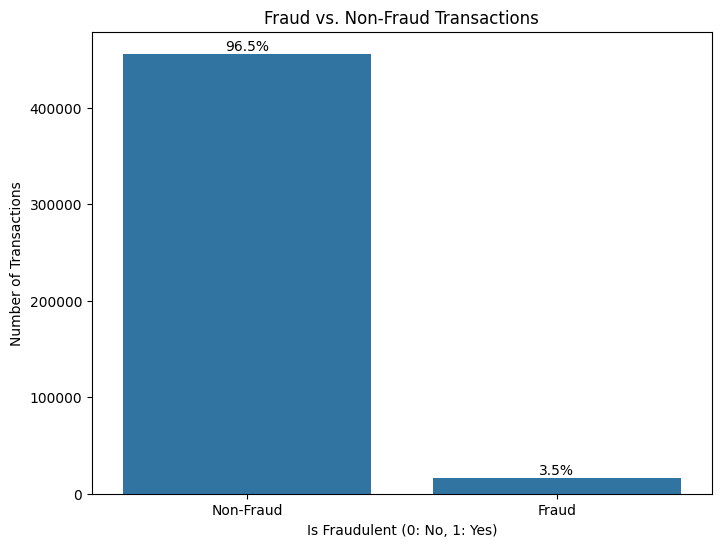

In [15]:
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='isFraud', data=train_df_merged)
plt.title('Fraud vs. Non-Fraud Transactions')
plt.xlabel('Is Fraudulent (0: No, 1: Yes)')
plt.ylabel('Number of Transactions')
plt.xticks(ticks=[0, 1], labels=['Non-Fraud', 'Fraud'])

total = len(train_df_merged['isFraud'])
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.show()

This is a large, mostly numeric table with identity and transaction fields. The EDA subset contains the earlier 80% of transactions; the last 20% is not inspected against `isFraud` here. Memory is reduced by downcasting numeric values before the plots below.

# Missing data exploration

I will check which columns contain missing data, how much of the data is missing and does the missing data have a relationship with the target(in this case is fraud).

In [16]:
train_identity_missing = missing_values_report(df=train_df_merged, columns_to_skip_prefix=[])
train_identity_missing_report = train_identity_missing.sort_values(by='present_percent', ascending=False)
train_identity_missing_report.head(20)

,column,dtype,total_count,present_count,present_percent,missing_count,missing_percent
433,TransactionID,int32,472432,472432,1.0,0,0.0
416,TransactionDT,int32,472432,472432,1.0,0,0.0
415,TransactionAmt,float32,472432,472432,1.0,0,0.0
414,card1,int16,472432,472432,1.0,0,0.0
424,C5,float32,472432,472432,1.0,0,0.0
423,C4,float32,472432,472432,1.0,0,0.0
422,C7,float32,472432,472432,1.0,0,0.0
421,C3,float32,472432,472432,1.0,0,0.0
420,C2,float32,472432,472432,1.0,0,0.0
419,C1,float32,472432,472432,1.0,0,0.0


Although useful information is contained in this table 434 rows are hard to grasp at glance. An interactive plot is needed for further inspection.

In [17]:
sorted_report = train_identity_missing_report.sort_values(by='missing_percent', ascending=False)

fig = px.bar(
    sorted_report,
    x='column',
    y='missing_percent',
    color='column', # Color each bar by column name
    title='Percentage of Missing Values in train_df_merged (Sorted)',
    labels={'column': 'Column Name', 'missing_percent': 'Missing Percentage'},
)

fig.update_layout(
    xaxis_tickangle=-90,
    showlegend=False,
    height=600,
    width=1000
)

fig.show()

This chart is interactable!

Some categories are nearly 100% missing. Further inspection is needed to check if the missing values are signal or they should be removed.

It is also noticeable that most of the rows have missing values in the ID categoires.

In [18]:
missingness_target_report = get_missingness_vs_target_report(train_df_merged, target_col="isFraud", columns_to_skip_prefix=[])

In [19]:
plot_df = missingness_target_report.copy()

plot_df = plot_df[
    (plot_df["missing_count"] >= 1000) &
    (plot_df["present_count"] >= 1000)
].copy()

plot_df["missing_vs_present_diff_pct_points"] = (
    plot_df["missing_vs_present_diff"] * 100
)

plot_df["fraud_rate_diff_category"] = np.where(
    plot_df["missing_vs_present_diff"] > 0,
    "Higher fraud rate when missing",
    "Higher fraud rate when present"
)

top_missing_signal = (
    plot_df
    .sort_values(
        "missing_vs_present_diff_pct_points",
        key=abs,
        ascending=False
    )
    .head(30)
)

fig = px.bar(
    top_missing_signal,
    x="column",
    y="missing_vs_present_diff_pct_points",
    color="fraud_rate_diff_category",
    title="Fraud-rate difference when feature is missing vs present",
    labels={
        "column": "Feature",
        "missing_vs_present_diff_pct_points": "Fraud-rate difference, percentage points",
        "fraud_rate_diff_category": "Direction"
    },
)

fig.update_layout(
    xaxis_tickangle=-90,
    height=600,
    width=1000,
)

fig.show()

1. For some Vesta-engineered and match-related features, missingness is associated with a higher fraud rate. These columns may be useful not only through their actual values, but also through whether the value exists at all.
2. For another group of features, fraud rate is higher when the value is present. This suggests that the availability of certain identity, device, or time-difference information may itself be a fraud-related signal.

> **Important Note:** Because missingness is associated with the target, preprocessing should preserve this information. In later modeling notebooks, we should test imputation with missing indicators instead of simple imputation only.

# Exploratory Data Analysis

I will focus on the features that are directly interpretable. Vesta-engineered features and identity features will be inspected later. So far, the missingness patterns in these columns suggest that missing data may contain signal related to fraudulent and non-fraudulent transactions.

## Data description

I don't have much information about the data other than:

1. TransactionID - unique ID
2. TransactionDT - time since a reference point (seconds, not real timestamp)
3. TransactionAmt - transaction amount
4. ProductCD - product category (W, C, R, H, S)
5. card1-card6 - card-related info (bank, type, etc.)
6. addr1, addr2 - billing region (masked)
7. dist1, dist2 - distance features (e.g., billing vs shipping)
8. P_emaildomain, R_emaildomain - purchaser / recipient email domains
9. DeviceType, DeviceInfo - device metadata
10. C1-C14, D1-D15, M1-M9 - aggregated behavioral / historical features (partially known patterns)



## TransactionDT

### Fraudulent transactions per hour

In [20]:
SECONDS_IN_HOUR = 60 * 60
SECONDS_IN_DAY = 24 * SECONDS_IN_HOUR

train_df_merged["TransactionDay"] = (
    train_df_merged["TransactionDT"] // SECONDS_IN_DAY
).astype(int)

train_df_merged["TransactionHour"] = (
    (train_df_merged["TransactionDT"] // SECONDS_IN_HOUR) % 24
).astype(int)

hourly_fraud_rate = fraud_rate_by_category(train_df_merged, "TransactionHour")
#display(hourly_fraud_rate)

In [21]:
fig = px.bar(
    hourly_fraud_rate,
    x='TransactionHour',
    y='fraud_rate',
    title='Fraud Rate by Transaction Hour',
    labels={
        'TransactionHour': 'Transaction Hour (0-23)',
        'fraud_rate': 'Fraud Rate (Mean isFraud)'
    },
    height=500,
    width=800
)

fig.update_layout(
    xaxis_tickangle=-45,
    xaxis_dtick=1 # Ensure all hours are displayed
)

fig.show()

### Fraudulent transactions per day


In [22]:
daily_fraud_rate = fraud_rate_by_category(train_df_merged, "TransactionDay")
#display(daily_fraud_rate.head())

In [23]:
fig = px.bar(
    daily_fraud_rate,
    x='TransactionDay',
    y='fraud_rate',
    title='Fraud Rate by Transaction Day',
    labels={
        'TransactionDay': 'Transaction Day',
        'fraud_rate': 'Fraud Rate (Mean isFraud)'
    },
    height=500,
    width=800
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

### Time patterns

`TransactionDT` is relative time, so it does not identify calendar dates or holidays. The plots above describe only the earlier-period EDA subset. Rerun them before interpreting any daily or hourly pattern; the later evaluation period is excluded.

## TransactionAmt

In [24]:
numeric_feature_report(train_df_merged, "TransactionAmt")

,TransactionAmt
count,472432.000000
mean,134.401382
std,237.559586
min,0.251000
25%,42.950001
50%,68.949997
75%,125.000000
max,31937.390625


Missing rate: 0.0
Skew: 16.428814


,count,mean,median,std,min,max
isFraud,,,,,,
0,455833,133.868332,68.500000,237.848862,0.251,31937.390625
1,16599,149.039734,76.128998,228.947800,0.292,5191.000000


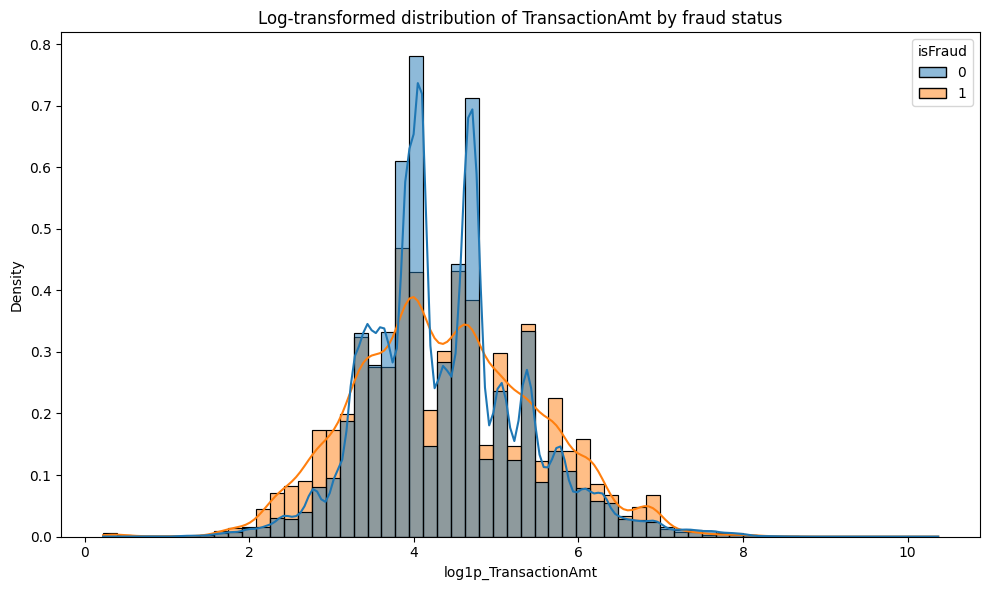

In [25]:
plot_numeric_distribution_by_target(
    train_df_merged,
    column="TransactionAmt",
    target_col="isFraud",
    log_transform=True,
)

The histogram above shows the distribution of transaction amounts for both fraudulent and non-fraudulent transactions.

Because TransactionAmt is usually right-skewed(many small transactions and a few very large transactions) I used log1p which compresses larger values and the distribution becomes easier to compare.

> Fraudulent transactions are more dispersed and may include proportionally more medium/high transaction amounts, while non-fraud transactions are more concentrated around common transaction amount ranges.

> There is huge overlap, so by itself TransactionAmt may not be enough to distinguish between fraudulent and non-fraudulent transactions. But combined with other features it may carry information.



## Product Category

In [26]:
product_summary = fraud_rate_by_category(
    train_df_merged,
    column="ProductCD",
    min_count=100,
)

display(product_summary)

,ProductCD,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,C,56410,6391,0.113296,0.385023
1,S,8127,503,0.061892,0.030303
2,H,29691,1377,0.046378,0.082957
3,R,32203,1169,0.036301,0.070426
4,W,346001,7159,0.020691,0.431291


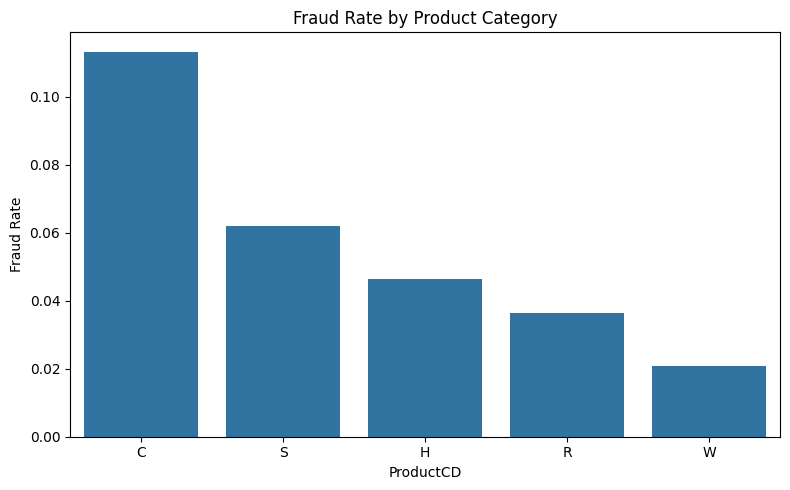

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_summary,
    x="ProductCD",
    y="fraud_rate",
)

plt.title("Fraud Rate by Product Category")
plt.xlabel("ProductCD")
plt.ylabel("Fraud Rate")
plt.tight_layout()
plt.show()

ProductCD shows different fraud rates across product categories. Category C appears to have the highest fraud rate, while category W has the lowest fraud rate. Transactions in ProductCD category C have a higher observed fraud rate in the training data.

> This suggests that ProductCD contains useful predictive signal. However, fraud rate should be interpreted together with total transaction count and fraud share, because a category can be high-risk but still contribute a small number of total fraud cases.

> Category C appears higher-risk, while W appears common/lower-risk.

## Card Info card1-card6
The card features are anonymized card-related variables. Some behave like categorical identifiers, while others are numeric encoded values. I first inspect fraud contribution by card type, then compare fraud rate to estimate relative risk.

In [28]:
card4_summary = fraud_rate_by_category(
    train_df_merged,
    column="card4",
    min_count=100,
)

display(card4_summary)

,card4,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,discover,5394,401,0.074342,0.024158
1,mastercard,150862,5266,0.034906,0.317248
2,visa,308141,10700,0.034724,0.644617
3,NaN,833,26,0.031212,0.001566
4,american express,7202,206,0.028603,0.012410


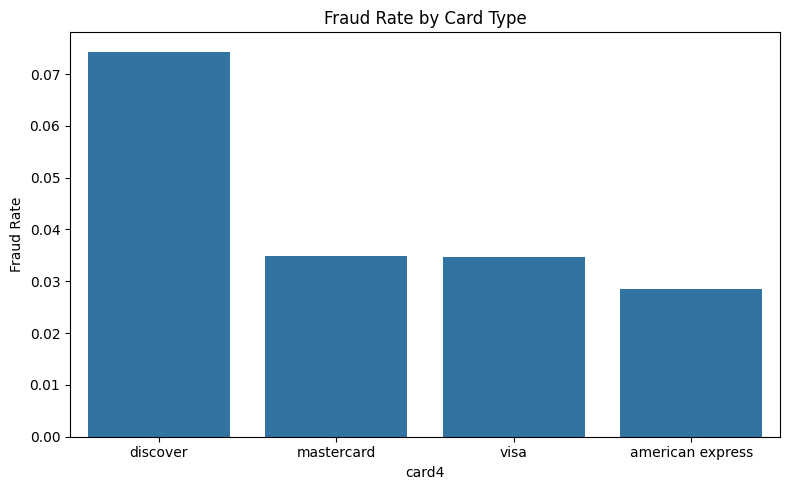

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=card4_summary,
    x="card4",
    y="fraud_rate",
)

plt.title("Fraud Rate by Card Type")
plt.xlabel("card4")
plt.ylabel("Fraud Rate")
plt.tight_layout()
plt.show()

In [30]:
card6_summary = fraud_rate_by_category(
    train_df_merged,
    column="card6",
    min_count=100,
)

display(card6_summary)

,card6,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,credit,121716,8189,0.067280,0.493343
1,NaN,828,24,0.028986,0.001446
2,debit,349843,8386,0.023971,0.505211


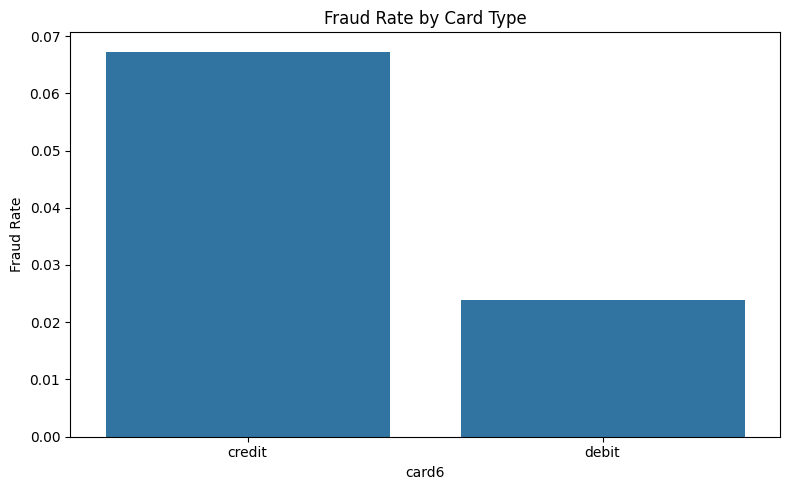

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=card6_summary,
    x="card6",
    y="fraud_rate",
)

plt.title("Fraud Rate by Card Type")
plt.xlabel("card6")
plt.ylabel("Fraud Rate")
plt.tight_layout()
plt.show()

card4 and card6 behave like categorical card-related features. The fraud-rate summaries show that fraud risk differs by card category. This is more informative than looking only at fraud counts, because common categories may contribute many fraud cases simply because they occur often.

card1, card2, card3, and card5 are stored as numeric values, but they may represent encoded identifiers rather than continuous measurements. Therefore, I will not interpret them as ordinary numeric variables in this EDA. In modeling, they should be tested as categorical-like encoded features or handled carefully with tree-based models.

## Address Features

In [32]:
addr1_summary = fraud_rate_by_category(
    train_df_merged,
    column="addr1",
    min_count=1000,
)

display(addr1_summary.head(20))

,addr1,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,NaN,53761,6128,0.113986,0.369179
1,122.0,1343,116,0.086374,0.006988
2,308.0,1084,80,0.073801,0.004820
3,324.0,1783,108,0.060572,0.006506
4,203.0,2984,141,0.047252,0.008494
5,226.0,3943,177,0.044890,0.010663
6,170.0,1599,60,0.037523,0.003615
7,476.0,7651,277,0.036204,0.016688
8,269.0,4994,180,0.036043,0.010844
9,330.0,19826,634,0.031978,0.038195


In [33]:
addr2_summary = fraud_rate_by_category(
    train_df_merged,
    column="addr2",
    min_count=100,
)

display(addr2_summary.head(20))

,addr2,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,96.0,564,66,0.117021,0.003976
1,NaN,53761,6128,0.113986,0.369179
2,60.0,2797,272,0.097247,0.016387
3,87.0,414740,10063,0.024263,0.606241


addr1 and addr2 are anonymized address-related features. Although they are stored as numeric values, they behave more like encoded categorical identifiers than continuous measurements.

addr1 contains several values with fraud rates above the global fraud rate, suggesting useful address-related signal. addr2 is dominated by one common value, but less frequent values may have higher fraud rates. These features should therefore be treated as categorical-like encoded variables rather than ordinary continuous numeric features.

## Distance features



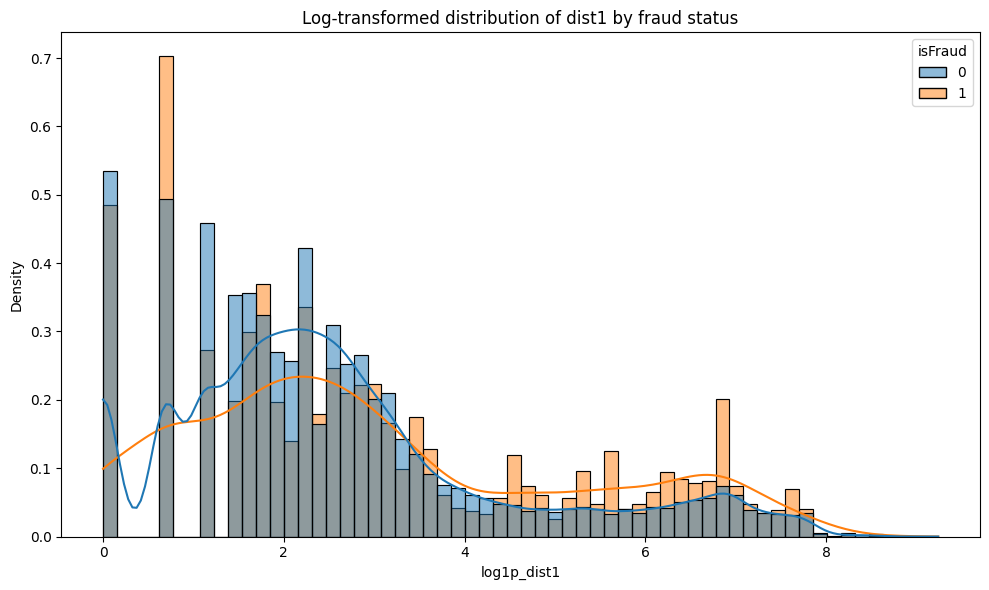

In [34]:
plot_numeric_distribution_by_target(train_df_merged, column="dist1", target_col="isFraud", log_transform=True)

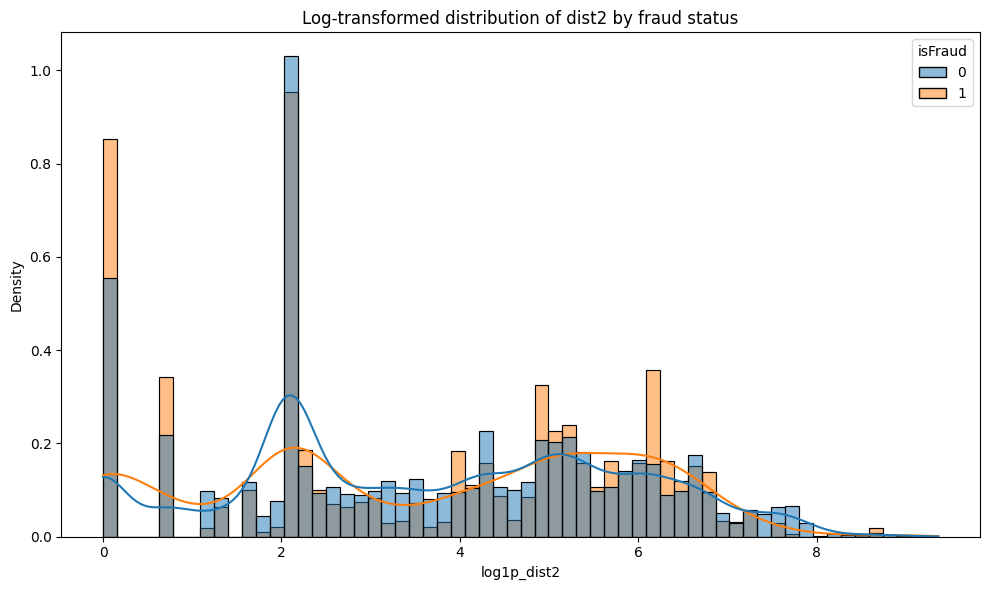

In [35]:
plot_numeric_distribution_by_target(train_df_merged, column="dist2", target_col="isFraud", log_transform=True)

In [36]:
dist_missingness_report = missingness_target_report[
    missingness_target_report['column'].isin(['dist1', 'dist2'])
]
display(dist_missingness_report)

,column,dtype,missing_count,missing_percent,present_count,present_percent,fraud_count_when_missing,fraud_count_when_present,fraud_rate_when_missing,fraud_rate_when_present,global_fraud_rate,missing_vs_present_diff,missing_vs_present_ratio,missing_vs_present_diff_pct_points
50,dist1,float32,287157,60.782716,185275,39.217284,12901,3698,0.044927,0.019960,0.035135,0.024967,2.250888,2.496712
402,dist2,float32,440332,93.205371,32100,6.794629,13556,3043,0.030786,0.094798,0.035135,-0.064012,0.324754,-6.401165


dist1 and dist2 are anonymized distance-like numeric features. Their exact semantic meaning is not provided, so I avoid interpreting them as specific real-world distances.

The log-transformed distributions help inspect these highly skewed features. The missingness report suggests that missingness itself may carry predictive signal: missing dist1 is associated with a higher fraud rate, while missing dist2 is associated with a lower fraud rate.

For modeling, I will preserve missingness using indicator features and test raw or log-transformed versions depending on the model type.

## P_emaildomain \ R_emaildomain

In [37]:
p_email_summary = fraud_rate_by_category(
    train_df_merged,
    column="P_emaildomain",
    min_count=1000,
)

display(p_email_summary.head(20))

,P_emaildomain,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,outlook.com,4080,374,0.091667,0.022531
1,hotmail.com,37158,1933,0.052021,0.116453
2,gmail.com,182692,8039,0.044003,0.484306
3,live.com,2475,79,0.031919,0.004759
4,icloud.com,5031,160,0.031803,0.009639
5,comcast.net,6496,195,0.030018,0.011748
6,NaN,73586,2195,0.029829,0.132237
7,bellsouth.net,1580,45,0.028481,0.002711
8,anonymous.com,29961,697,0.023264,0.041990
9,yahoo.com,80854,1854,0.022930,0.111693


In [38]:
r_email_summary = fraud_rate_by_category(
    train_df_merged,
    column="R_emaildomain",
    min_count=1000,
)

display(r_email_summary.head(20))

,R_emaildomain,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,outlook.com,2035,319,0.156757,0.019218
1,icloud.com,1138,135,0.118629,0.008133
2,gmail.com,47290,5446,0.115162,0.328092
3,hotmail.com,22984,1713,0.074530,0.103199
4,yahoo.com,8879,518,0.058340,0.031207
5,aol.com,3254,120,0.036878,0.007229
6,anonymous.com,17271,493,0.028545,0.029701
7,NaN,358812,7586,0.021142,0.457015
8,comcast.net,1578,21,0.013308,0.001265
9,yahoo.com.mx,1256,15,0.011943,0.000904


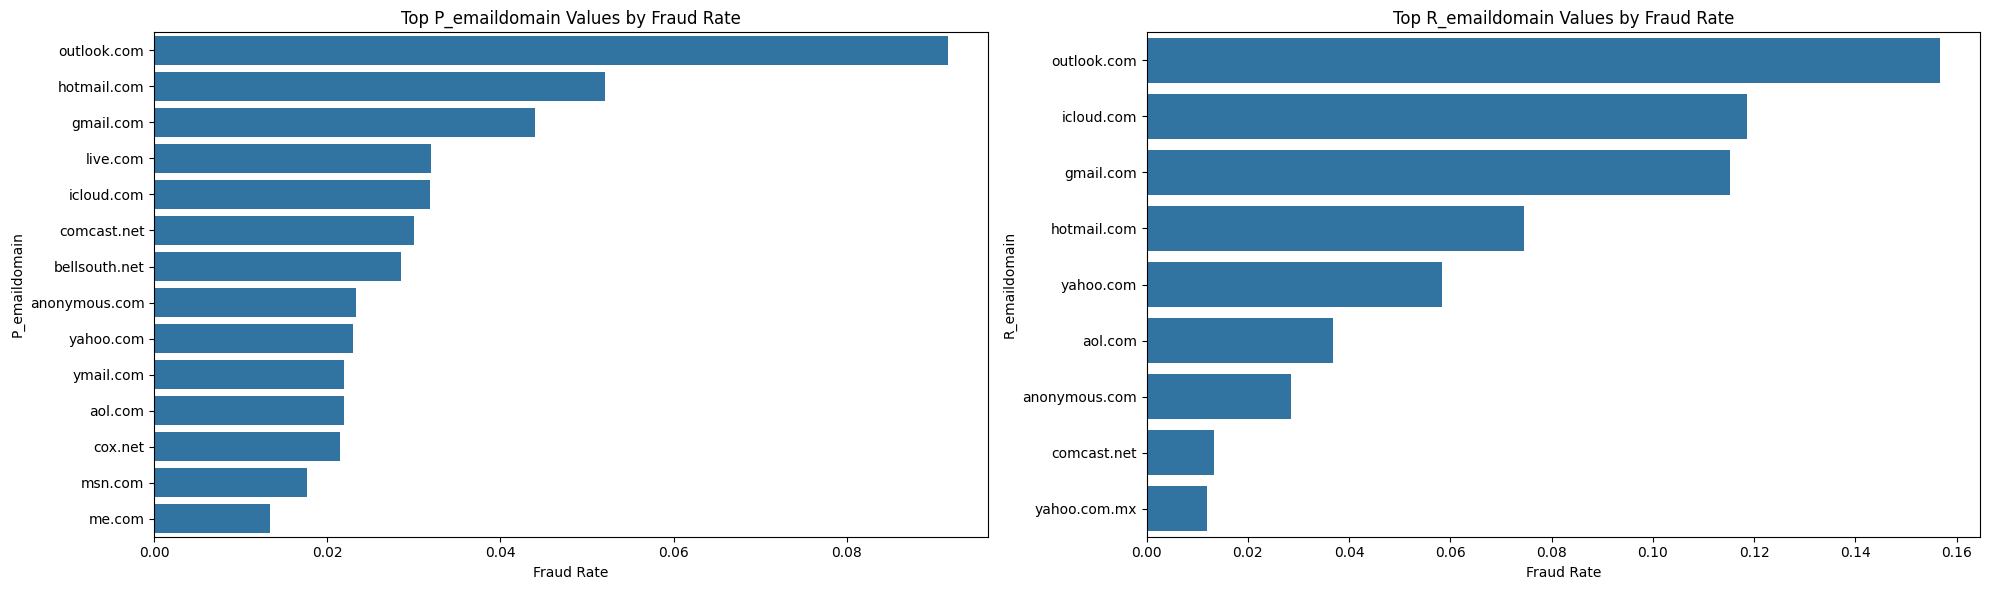

In [39]:
fig, axs = plt.subplots(1, 2, figsize=(20, 6))

# Plot for P_emaildomain
sns.barplot(
    data=p_email_summary.head(15),
    y="P_emaildomain",
    x="fraud_rate",
    ax=axs[0]
)
axs[0].set_title("Top P_emaildomain Values by Fraud Rate")
axs[0].set_xlabel("Fraud Rate")
axs[0].set_ylabel("P_emaildomain")

# Plot for R_emaildomain
sns.barplot(
    data=r_email_summary.head(15),
    y="R_emaildomain",
    x="fraud_rate",
    ax=axs[1]
)
axs[1].set_title("Top R_emaildomain Values by Fraud Rate")
axs[1].set_xlabel("Fraud Rate")
axs[1].set_ylabel("R_emaildomain")

plt.tight_layout()
plt.show()

Large email providers dominate total transaction volume, so fraud counts alone are misleading. Fraud rate and fraud share should be considered together. The email domains with highest fraud_rate  are outlook.com and hotmail.com.

> **Important note** For modeling, email domains should likely be grouped to reduce cardinality. A reasonable approach is to keep frequent domains and group rare domains as "Other", but the threshold should be chosen based on validation performance rather than fixed manually.

## Device Type

In [40]:
device_type_summary = fraud_rate_by_category(
    train_df_merged,
    column="DeviceType",
    min_count=100,
)

display(device_type_summary)

,DeviceType,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,mobile,46093,4565,0.099039,0.275017
1,desktop,71545,4465,0.062408,0.268992
2,NaN,354794,7569,0.021334,0.455991


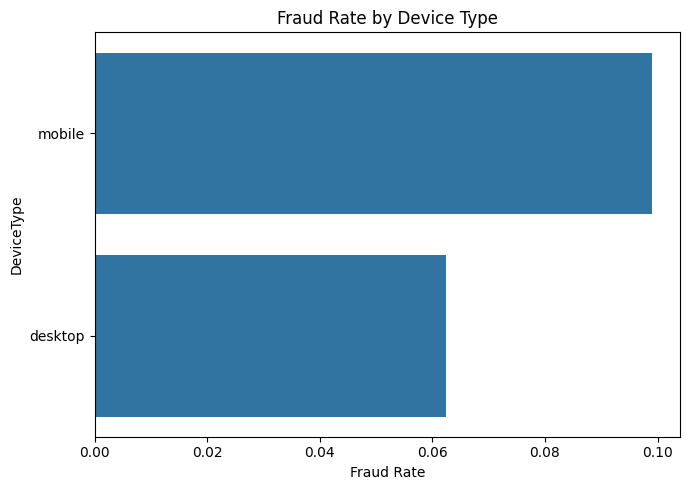

In [41]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=device_type_summary,
    y="DeviceType",
    x="fraud_rate",
)

plt.title("Fraud Rate by Device Type")
plt.xlabel("Fraud Rate")
plt.ylabel("DeviceType")
plt.tight_layout()
plt.show()

Fraudulent transactions are split almost evenly between mobile and desktop devices, but the fraud-rate comparison shows that mobile transactions have a higher observed fraud rate.

> Device Type contains useful information and should be encoded.

## Device Info

In [42]:
device_info_summary = fraud_rate_by_category(
    train_df_merged,
    column="DeviceInfo",
    min_count=500,
)

display(device_info_summary.head(20))

,DeviceInfo,total_transactions,fraud_transactions,fraud_rate,fraud_share
0,rv:57.0,957,103,0.107628,0.006205
1,Windows,39681,2465,0.062120,0.148503
2,iOS Device,17083,1048,0.061348,0.063136
3,rv:11.0,1651,69,0.041793,0.004157
4,NaN,372896,9691,0.025988,0.583830
5,MacOS,10843,201,0.018537,0.012109
6,Trident/7.0,6453,74,0.011468,0.004458


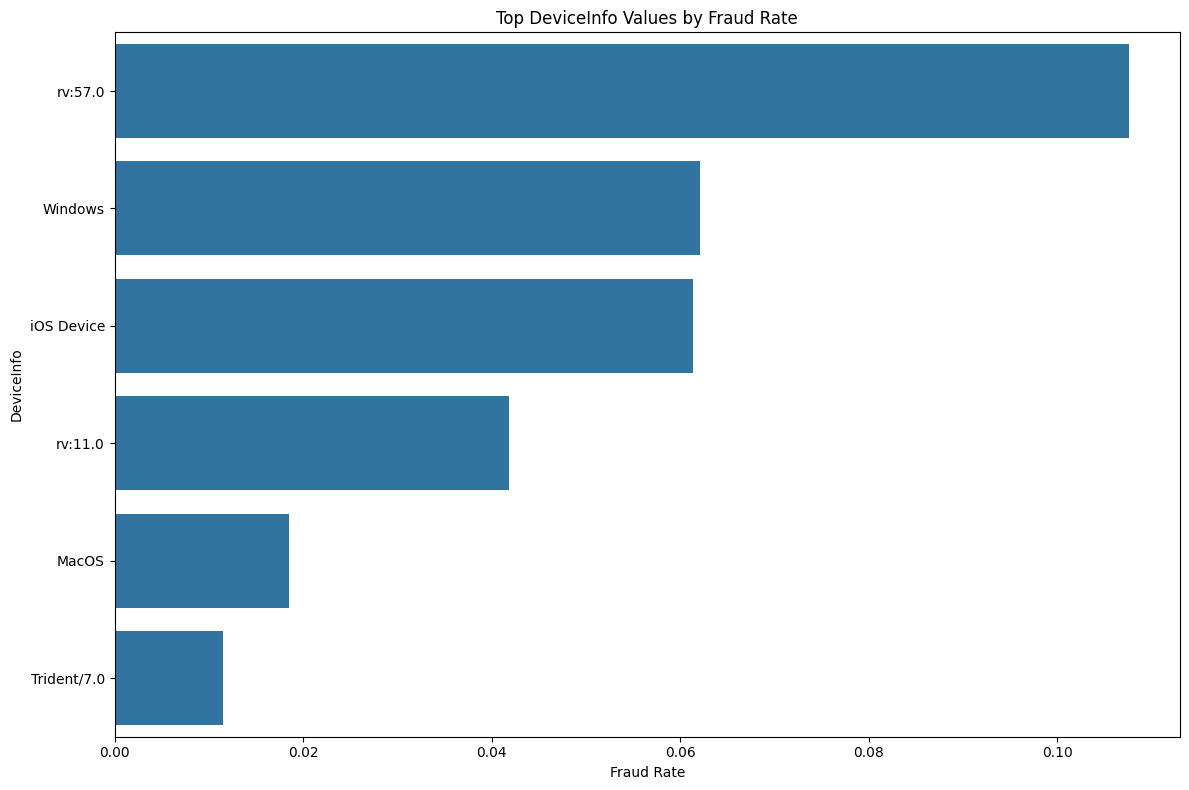

In [43]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=device_info_summary.head(20),
    y="DeviceInfo",
    x="fraud_rate",
)

plt.title("Top DeviceInfo Values by Fraud Rate")
plt.xlabel("Fraud Rate")
plt.ylabel("DeviceInfo")
plt.tight_layout()
plt.show()

DeviceInfo is a high-cardinality device metadata feature. Some values show higher fraud rates, but this feature is noisy because many device values occur rarely. To avoid unstable conclusions, I filter to values with at least 500 transactions.

For modeling, DeviceInfo should not be one-hot encoded naively without grouping. A reasonable first approach is to keep frequent DeviceInfo values, group rare values as "Other", and preserve missing values as a separate category.

## Vesta-engineered C, D, and M Features

In [44]:
C_COLS = [f"C{i}" for i in range(1, 15)]
D_COLS = [f"D{i}" for i in range(1, 16)]
M_COLS = [f"M{i}" for i in range(1, 10)]

cdm_cols = C_COLS + D_COLS + M_COLS
cdm_cols = [col for col in cdm_cols if col in train_df_merged.columns]

cdm_missingness_report = get_missingness_vs_target_report(
    train_df_merged[cdm_cols + ["isFraud"]],
    target_col="isFraud",
)

display(
    cdm_missingness_report
    .sort_values("missing_vs_present_diff", ascending=False)
    .head(20)
)

,column,dtype,missing_count,missing_percent,present_count,present_percent,fraud_count_when_missing,fraud_count_when_present,fraud_rate_when_missing,fraud_rate_when_present,global_fraud_rate,missing_vs_present_diff,missing_vs_present_ratio,missing_vs_present_diff_pct_points
0,M6,object,141415,29.933408,331017,70.066592,9664,6935,0.068338,0.020951,0.035135,0.047387,3.261860,4.738729
1,M3,object,238295,50.440063,234137,49.559937,11905,4694,0.049959,0.020048,0.035135,0.029911,2.491962,2.991099
2,M1,object,238295,50.440063,234137,49.559937,11905,4694,0.049959,0.020048,0.035135,0.029911,2.491962,2.991099
3,M2,object,238295,50.440063,234137,49.559937,11905,4694,0.049959,0.020048,0.035135,0.029911,2.491962,2.991099
4,D11,float32,245973,52.065271,226459,47.934729,12115,4484,0.049253,0.019800,0.035135,0.029453,2.487482,2.945288
5,M8,object,299974,63.495699,172458,36.504301,13173,3426,0.043914,0.019866,0.035135,0.024048,2.210533,2.404810
6,M9,object,299974,63.495699,172458,36.504301,13173,3426,0.043914,0.019866,0.035135,0.024048,2.210533,2.404810
7,M7,object,299980,63.496969,172452,36.503031,13173,3426,0.043913,0.019866,0.035135,0.024047,2.210412,2.404653
8,D2,float32,231263,48.951595,241169,51.048405,10303,6296,0.044551,0.026106,0.035135,0.018445,1.706531,1.844483
9,D10,float32,66391,14.053028,406041,85.946972,3288,13311,0.049525,0.032782,0.035135,0.016742,1.510712,1.674238


In [45]:
cdm_summary = pd.DataFrame({
    "column": cdm_cols,
    "missing_rate": [train_df_merged[col].isna().mean() for col in cdm_cols],
    "n_unique": [train_df_merged[col].nunique(dropna=False) for col in cdm_cols],
    "dtype": [train_df_merged[col].dtype for col in cdm_cols],
})
display(cdm_summary.sort_values("missing_rate", ascending=False))

,column,missing_rate,n_unique,dtype
20,D7,0.936617,569,float32
26,D13,0.896339,528,float32
27,D14,0.894512,764,float32
25,D12,0.888443,601,float32
19,D6,0.876209,782,float32
22,D9,0.869590,25,float32
21,D8,0.869590,11360,float32
35,M7,0.634970,3,object
36,M8,0.634957,3,object
37,M9,0.634957,3,object


The C, D, and M columns are anonymized Vesta-engineered features. I do not try to assign semantic meaning to each column. Instead, I inspect them systematically through missingness and target relationship.

Several C/D/M features show missingness patterns associated with fraud, so they should not be dropped automatically. For modeling, C and D features will be treated as numeric engineered features, while M features will be treated as categorical match flags with missing values preserved.

# EDA Summary

Main findings:

1. The dataset is highly imbalanced, with fraudulent transactions representing a small minority of all transactions.
2. Missingness is strongly associated with fraud for several feature groups, so missing values should not be treated as random noise.
3. TransactionDT is a relative timestamp. Derived relative day and hour features show variation in fraud rate over time, but they cannot be mapped to real calendar dates.
4. TransactionAmt is strongly right-skewed. A log1p transformation makes the distribution easier to inspect, but fraudulent and non-fraudulent transactions still overlap heavily.
5. ProductCD, card features, address features, email domains, and device-related features show fraud-rate differences across categories.
6. Several anonymized engineered features appear potentially useful and should be evaluated during modeling rather than dropped only because they lack semantic interpretation.
7. Several numeric-looking columns should not automatically be treated as continuous measurements. In particular, card1, card2, card3, card5, addr1, and addr2 appear to represent encoded categorical or identifier-like values, so they should be handled carefully during preprocessing, especially for distance-based and linear models.

# Modeling plan

1. Keep the latest 20% of transactions by `TransactionDT` as a time holdout.
2. Perform target-aware EDA, supervised feature selection, and preprocessing fitting only within the earlier 80%.
3. Use an inner time split for model and threshold tuning.
4. Compare a simple baseline with tree models using PR-AUC as the primary metric; report ROC-AUC, precision, recall, and F1 as supporting measures.
5. Treat card/address identifiers and high-cardinality text fields as categorical where appropriate, and preserve useful missingness information.
6. Interpret the chosen model after fitting. Because earlier project runs examined the original holdout, obtain a fresh later labeled period for a truly untouched final estimate.

| Finding | Modeling decision |
|---|---|
| Missingness is target-associated | Add missing indicators or preserve missing values as an explicit category. |
| ProductCD fraud rates differ | Encode ProductCD as a categorical feature. |
| DeviceInfo is high-cardinality | Group rare values before encoding. |
| TransactionAmt is skewed | Test `log1p(TransactionAmt)` for linear models. |
| card/addr numeric columns act categorical | Avoid treating all numeric columns as continuous measurements. |
| Dataset is imbalanced | Use PR-AUC, recall, and threshold tuning instead of relying on accuracy. |
| Anonymized C/D/M features show potential signal | Inspect systematically and evaluate them during modeling instead of dropping them only because they lack semantic meaning. |